# Análisis del baseline en test

Compara los modelos sin entrenar sobre `datos/test.jsonl`: 20 árboles en cada uno de los 8 niveles. Lee todos los `BaseLines/<modelo>/baseline_test.jsonl`, así que un modelo nuevo aparece solo.

**Mismos intentos para todos:** DeepSeek, Llama y OLMo tienen 6 intentos por árbol en los niveles 2 a 6, y el resto, 4. Si se usaran todos, esos niveles pesarían más en sus promedios. Por eso el análisis usa los primeros `INTENTOS` intentos de cada árbol, y deja la versión con todos los intentos al final, como referencia.

Las columnas de proporción van de 0 a 1.

- **pass@1:** intentos que logran el óptimo.
- **pass@4:** árboles donde al menos uno de sus 4 intentos logra el óptimo.
- **recompensa:** media del episodio. Igualar el mejor atajo vale 0,5, y una respuesta inválida, -1.
- **supera_voraz / supera_atajos:** veces que el modelo superó la regla simple, o al mejor atajo.
- **invalidos:** respuestas sin un formato válido.
- **cortes:** episodios que agotaron el pensamiento, y cuya respuesta fue forzada.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from evaluacion import leer_resultados, resumir, resumir_pass

INTENTOS = 4  # Primeros intentos de cada árbol que se usan: todos los modelos tienen al menos 4
K = 4         # El k de pass@k
RUTAS = sorted(str(ruta) for ruta in Path('BaseLines').glob('*/baseline_test.jsonl'))

episodios = pd.DataFrame([fila for ruta in RUTAS for fila in leer_resultados(ruta)])
primeros = episodios[episodios['intento'] <= INTENTOS]
MODELOS = sorted(episodios['modelo'].unique())

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
print('Modelos:', MODELOS)

Modelos: ['DeepSeek R1 Distill 1.5B', 'Llama 3.2 1B', 'Ministral 3 3B Reasoning 4bit', 'OLMo 2 1B', 'Qwen 3.5 2B']


## Cobertura

Episodios guardados por modelo y nivel, con todos los intentos. Con 20 árboles por nivel, 80 son 4 intentos por árbol y 120, 6.

In [2]:
cobertura = episodios.pivot_table(index='modelo', columns='nivel', values='recompensa', aggfunc='size', fill_value=0)
cobertura['total'] = cobertura.sum(axis=1)
cobertura['minimo_por_arbol'] = episodios.groupby(['modelo', 'episodio']).size().groupby('modelo').min()
cobertura

nivel,1,2,3,4,5,6,7,8,total,minimo_por_arbol
modelo,,,,,,,,,,
DeepSeek R1 Distill 1.5B,80,120,120,120,120,120,80,80,840,4
Llama 3.2 1B,80,120,120,120,120,120,80,80,840,4
Ministral 3 3B Reasoning 4bit,80,80,80,80,80,80,80,80,640,4
OLMo 2 1B,80,120,120,120,120,120,80,80,840,4
Qwen 3.5 2B,80,80,80,80,80,80,80,80,640,4


## Resumen por modelo

Con los primeros `INTENTOS` intentos de cada árbol: 640 episodios por modelo. Ordenado por pass@4.

In [3]:
resumen = resumir_pass(RUTAS, k=K, por=['modelo'], intentos=INTENTOS)[['pass@1', f'pass@{K}']].join(
    resumir(RUTAS, por=['modelo'], intentos=INTENTOS)[
        ['episodios', 'recompensa', 'supera_voraz', 'supera_atajos', 'invalidos', 'cortes', 'tokens', 'segundos']
    ]
).sort_values(f'pass@{K}', ascending=False)
resumen

,pass@1,pass@4,episodios,recompensa,supera_voraz,supera_atajos,invalidos,cortes,tokens,segundos
modelo,,,,,,,,,,
Ministral 3 3B Reasoning 4bit,0.292,0.475,640,0.328,0.528,0.191,0.123,0.717,3124.127,135.277
DeepSeek R1 Distill 1.5B,0.086,0.169,640,0.255,0.338,0.056,0.020,0.983,3404.317,91.805
Qwen 3.5 2B,0.059,0.125,640,0.178,0.255,0.017,0.048,1.000,3413.934,88.481
Llama 3.2 1B,0.059,0.100,640,0.235,0.270,0.033,0.000,0.000,4.714,2.045
OLMo 2 1B,0.062,0.075,640,-0.082,0.220,0.019,0.278,0.000,18.772,3.728


## Intervalos de confianza

Intervalo del 95 % por bootstrap: se remuestrean los árboles dentro de cada nivel, 2000 veces. Con 4 intentos por árbol, pass@4 es la proporción de árboles con algún óptimo. Si los intervalos de dos modelos se superponen mucho, la diferencia entre ellos puede deberse a los árboles que tocaron.

In [4]:
# Una fila por árbol: si tuvo algún óptimo, y su recompensa e inválidos medios en sus intentos.
arboles = primeros.groupby(['modelo', 'nivel', 'episodio'])['recompensa'].agg(
    paso=lambda r: (r == 1.0).any(),
    recompensa='mean',
    invalidos=lambda r: (r == -1.0).mean(),
).reset_index()

rng = np.random.default_rng(0)


def intervalo(grupo, columna, repeticiones=2000):
    # Cada nivel tiene los mismos árboles, así que la media de las medias por nivel es la media total.
    por_nivel = [nivel[columna].to_numpy(float) for _, nivel in grupo.groupby('nivel')]
    medias = np.mean([rng.choice(v, (repeticiones, len(v))).mean(axis=1) for v in por_nivel], axis=0)
    return np.percentile(medias, [2.5, 97.5])


filas = []
for modelo, grupo in arboles.groupby('modelo'):
    fila = {'modelo': modelo}
    for columna, nombre in [('paso', f'pass@{K}'), ('recompensa', 'recompensa'), ('invalidos', 'invalidos')]:
        bajo, alto = intervalo(grupo, columna)
        fila |= {nombre: grupo[columna].mean(), f'{nombre}_bajo': bajo, f'{nombre}_alto': alto}
    filas.append(fila)

intervalos = pd.DataFrame(filas).set_index('modelo').loc[resumen.index].round(3)
intervalos

,pass@4,pass@4_bajo,pass@4_alto,recompensa,recompensa_bajo,recompensa_alto,invalidos,invalidos_bajo,invalidos_alto
modelo,,,,,,,,,
Ministral 3 3B Reasoning 4bit,0.475,0.431,0.513,0.328,0.285,0.369,0.123,0.100,0.147
DeepSeek R1 Distill 1.5B,0.169,0.125,0.219,0.255,0.228,0.282,0.020,0.011,0.031
Qwen 3.5 2B,0.125,0.081,0.162,0.178,0.149,0.205,0.048,0.033,0.066
Llama 3.2 1B,0.100,0.062,0.138,0.235,0.211,0.258,0.000,0.000,0.000
OLMo 2 1B,0.075,0.038,0.112,-0.082,-0.128,-0.034,0.278,0.248,0.309


## Por nivel

In [5]:
pass_nivel = resumir_pass(RUTAS, k=K, intentos=INTENTOS)[f'pass@{K}'].unstack('nivel').loc[resumen.index]
print(f'pass@{K}')
pass_nivel

pass@4


nivel,1,2,3,4,5,6,7,8
modelo,,,,,,,,
Ministral 3 3B Reasoning 4bit,1.00,1.00,0.95,0.45,0.4,0.0,0.0,0.0
DeepSeek R1 Distill 1.5B,0.50,0.45,0.40,0.00,0.0,0.0,0.0,0.0
Qwen 3.5 2B,0.50,0.45,0.05,0.00,0.0,0.0,0.0,0.0
Llama 3.2 1B,0.45,0.35,0.00,0.00,0.0,0.0,0.0,0.0
OLMo 2 1B,0.35,0.25,0.00,0.00,0.0,0.0,0.0,0.0


In [6]:
por_nivel = resumir(RUTAS, intentos=INTENTOS)
recompensa_nivel = por_nivel['recompensa'].unstack('nivel').loc[resumen.index]
print('recompensa media')
recompensa_nivel

recompensa media


nivel,1,2,3,4,5,6,7,8
modelo,,,,,,,,
Ministral 3 3B Reasoning 4bit,0.810,0.643,0.588,0.302,0.233,-0.097,0.090,0.057
DeepSeek R1 Distill 1.5B,0.551,0.488,0.428,0.260,0.149,0.099,0.035,0.031
Qwen 3.5 2B,0.569,0.378,0.234,0.146,0.089,0.048,-0.020,-0.021
Llama 3.2 1B,0.564,0.494,0.297,0.182,0.129,0.116,0.054,0.040
OLMo 2 1B,0.396,0.312,-0.052,-0.143,-0.334,-0.280,-0.286,-0.271


In [7]:
invalidos_nivel = por_nivel['invalidos'].unstack('nivel').loc[resumen.index]
print('invalidos')
invalidos_nivel

invalidos


nivel,1,2,3,4,5,6,7,8
modelo,,,,,,,,
Ministral 3 3B Reasoning 4bit,0.088,0.150,0.112,0.175,0.150,0.262,0.025,0.025
DeepSeek R1 Distill 1.5B,0.050,0.062,0.000,0.000,0.012,0.012,0.025,0.000
Qwen 3.5 2B,0.025,0.062,0.038,0.050,0.050,0.050,0.062,0.050
Llama 3.2 1B,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
OLMo 2 1B,0.150,0.162,0.262,0.300,0.400,0.338,0.325,0.288


## Gráficos

Cada modelo conserva su color y su marcador en todos los gráficos. Los valores exactos están en las tablas de arriba. Las barras negras son los intervalos del 95 %.

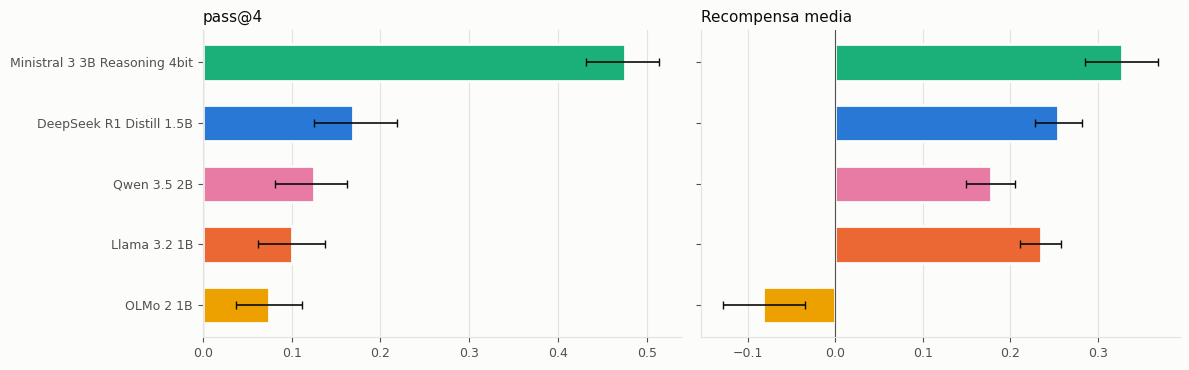

In [ ]:
COLORES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
MARCADORES = ['o', 's', 'D', '^', 'v', 'P', 'X', '*']
ESTILO = {m: dict(color=COLORES[i], marker=MARCADORES[i]) for i, m in enumerate(MODELOS)}  # Por modelo, no por rango
TINTA, TINTA_SUAVE, GRILLA = '#0b0b0b', '#52514e', '#e4e3df'


def ejes_sobrios(ax):
    ax.set_facecolor('#fcfcfb')
    for lado in ['top', 'right']:
        ax.spines[lado].set_visible(False)
    for lado in ['left', 'bottom']:
        ax.spines[lado].set_color(GRILLA)
    ax.tick_params(colors=TINTA_SUAVE, labelsize=9)
    ax.grid(color=GRILLA, linewidth=0.8)
    ax.set_axisbelow(True)


fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8), facecolor='#fcfcfb')
orden = list(resumen.index)[::-1]  # El mejor arriba
for ax, columna, titulo in [(ejes[0], f'pass@{K}', f'pass@{K}'), (ejes[1], 'recompensa', 'Recompensa media')]:
    valores = intervalos.loc[orden, columna]
    error = [valores - intervalos.loc[orden, f'{columna}_bajo'], intervalos.loc[orden, f'{columna}_alto'] - valores]
    ax.barh(orden, valores, height=0.6, color=[ESTILO[m]['color'] for m in orden], edgecolor='#fcfcfb', linewidth=2)
    ax.errorbar(valores, orden, xerr=error, fmt='none', ecolor=TINTA, elinewidth=1.2, capsize=3)
    ax.axvline(0, color=TINTA_SUAVE, linewidth=0.8)
    ax.set_title(titulo, color=TINTA, loc='left', fontsize=11)
    ejes_sobrios(ax)
    ax.grid(axis='y', visible=False)
ejes[1].set_yticklabels([])
fig.tight_layout()
plt.show()

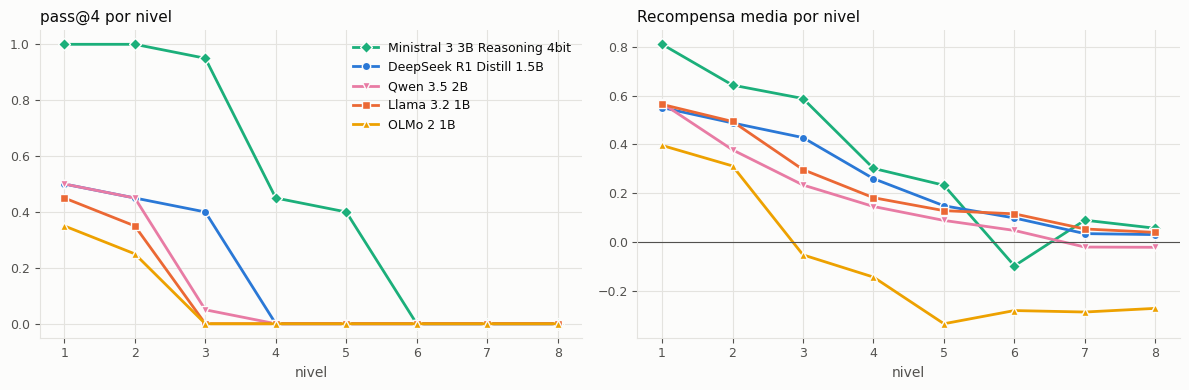

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4), facecolor='#fcfcfb', sharex=True)
for ax, tabla, titulo in [(ejes[0], pass_nivel, f'pass@{K} por nivel'), (ejes[1], recompensa_nivel, 'Recompensa media por nivel')]:
    for modelo in resumen.index:
        ax.plot(tabla.columns, tabla.loc[modelo], linewidth=2, markersize=6, label=modelo,
                markeredgecolor='#fcfcfb', markeredgewidth=1, **ESTILO[modelo])
    ax.set_title(titulo, color=TINTA, loc='left', fontsize=11)
    ax.set_xlabel('nivel', color=TINTA_SUAVE)
    ax.set_xticks(tabla.columns)
    ejes_sobrios(ax)
ejes[1].axhline(0, color=TINTA_SUAVE, linewidth=0.8)
ejes[0].legend(frameon=False, fontsize=9, labelcolor=TINTA)
fig.tight_layout()
plt.show()

## Ministral según cómo se ejecutó

En los niveles 2 a 6, los intentos 1 a 3 de Ministral corrieron con Transformers en 4 bits NF4, y el intento 4, en LM Studio con el GGUF Q4_K_M. Esta tabla compara las dos ejecuciones en esos niveles, y la siguiente muestra por qué se marcaron inválidas sus respuestas.

In [10]:
ministral = episodios[episodios['modelo'].str.startswith('Ministral') & episodios['nivel'].between(2, 6)].copy()
ministral['ejecucion'] = np.where(ministral['intento'] <= 3, 'Transformers NF4', 'LM Studio Q4_K_M')
ministral.groupby('ejecucion')['recompensa'].agg(
    episodios='size',
    recompensa='mean',
    optimos=lambda r: (r == 1.0).mean(),
    invalidos=lambda r: (r == -1.0).mean(),
).round(3)

,episodios,recompensa,optimos,invalidos
ejecucion,,,,
LM Studio Q4_K_M,100,0.531,0.280,0.000
Transformers NF4,300,0.268,0.297,0.227


In [15]:
episodios[episodios['recompensa'] == -1.0].groupby(['fin', 'error']).size().rename('episodios')

fin     error                                                                       
length  Hay nodos repetidos                                                               8
        Los nodos deben estar entre 1 y 15                                                2
        Los nodos deben estar entre 1 y 3                                                 1
        Los nodos deben estar entre 1 y 4                                                 2
        Los nodos deben estar entre 1 y 40                                                1
        No hay números de nodos entre > y <, ni una respuesta que solo tenga números     80
stop    No hay números de nodos entre > y <, ni una respuesta que solo tenga números    236
Name: episodios, dtype: int64

## Tablas en LaTeX

Una tabla por métrica, modelo contra nivel, y un resumen al final. Usan los primeros `INTENTOS` intentos de cada árbol, igual que el resto del análisis. Al volver a correr el notebook con resultados nuevos, basta copiar la salida al informe. Las tablas usan `[H]`, del paquete `float`.

In [ ]:
def tabla_latex(tabla, titulo, etiqueta, formato, columnas):
    # `columnas` son los encabezados de las columnas de `tabla`; si son niveles, se agrupan bajo "Nivel".
    por_nivel = columnas is None
    columnas = list(tabla.columns) if por_nivel else columnas
    lineas = [r'\begin{table}[H]', r'\centering', rf'\caption{{{titulo}}}', rf'\label{{{etiqueta}}}',
              r'\small', r'\setlength{\tabcolsep}{4pt}', rf'\begin{{tabular}}{{l{"c" * len(columnas)}}}', r'\hline']
    if por_nivel:
        lineas += [rf'\textbf{{Modelo}} & \multicolumn{{{len(columnas)}}}{{c}}{{\textbf{{Nivel}}}} \\',
                   ' & '.join([''] + [str(c) for c in columnas]) + r' \\']
    else:
        lineas.append(' & '.join([r'\textbf{Modelo}'] + [rf'\textbf{{{c}}}' for c in columnas]) + r' \\')
    lineas.append(r'\hline')
    for modelo, fila in tabla.iterrows():
        lineas.append(' & '.join([modelo] + [f(v) for f, v in zip(formato, fila)]) + r' \\')
    return '\n'.join(lineas + [r'\hline', r'\end{tabular}', r'\end{table}'])


tres, dos, porcentaje = '{:.3f}'.format, '{:.2f}'.format, lambda v: f'{100 * v:.1f}'
pass1_nivel = resumir_pass(RUTAS, k=K, intentos=INTENTOS)['pass@1'].unstack('nivel').loc[resumen.index]
nota = f'Primeros {INTENTOS} intentos de cada uno de los 20 árboles por nivel.'
tablas = [
    (pass1_nivel, f'pass@1 por modelo y nivel. {nota}', 'tab:pass1_nivel', tres),
    (pass_nivel, f'pass@{K} por modelo y nivel. {nota}', f'tab:pass{K}_nivel', dos),
    (recompensa_nivel, f'Recompensa media por modelo y nivel. {nota}', 'tab:recompensa_nivel', tres),
    (invalidos_nivel, rf'Respuestas inválidas (\%) por modelo y nivel. {nota}', 'tab:invalidos_nivel', porcentaje),
]
for tabla, titulo, etiqueta, formato in tablas:
    print(tabla_latex(tabla, titulo, etiqueta, [formato] * tabla.shape[1], None), end='\n\n')

print(tabla_latex(
    resumen[['pass@1', f'pass@{K}', 'recompensa', 'invalidos']],
    f'Resumen por modelo en los 8 niveles. {nota}', 'tab:resumen_baseline', [tres, tres, tres, porcentaje],
    ['pass@1', f'pass@{K}', 'Recompensa', r'Inválidas (\%)'],
))

## Conclusiones

Con los primeros 4 intentos de cada árbol:

- **Ministral 3 3B es claramente el mejor:** pass@4 de 0,475 (IC 95 %: 0,43–0,51), casi el triple que DeepSeek (0,169). Su intervalo no se superpone con el de ningún otro modelo. También tiene la mejor recompensa (0,328) y supera a la regla voraz en el 53 % de los episodios.
- **Es el único que resuelve árboles medianos:** pass@4 de 1,00 en los niveles 1 y 2, de 0,95 en el 3 y de 0,40–0,45 en los niveles 4 y 5. Los demás no pasan de 0,5 en ningún nivel y llegan a 0 desde el nivel 3 o 4.
- **Desde el nivel 6, ningún modelo logra el óptimo.** Las recompensas positivas de esos niveles vienen de soluciones parciales.
- **Entre los modelos chicos, las diferencias son pequeñas.** DeepSeek, Qwen y Llama tienen un pass@4 de 0,10 a 0,17, con intervalos que se superponen. En recompensa, DeepSeek (0,255) y Llama (0,235) quedan por encima de Qwen (0,178).
- **OLMo 2 1B es el único con recompensa negativa** (-0,082), porque el 28 % de sus respuestas son inválidas.
- **Las inválidas de Ministral (12 %) dependen de la ejecución:** en los niveles 2 a 6 son el 23 % con Transformers NF4 y el 0 % con LM Studio, con una tasa de óptimos parecida en las dos (~29 %). Casi todas son respuestas sin una lista de nodos legible, la mayoría tras agotar el pensamiento. Con todo en LM Studio, su recompensa probablemente sería mayor.
- **Llama no tiene inválidas, pero tampoco razona:** responde en ~5 tokens. Su recompensa positiva viene de soluciones parciales: el 90 % de sus respuestas queda por debajo del mejor atajo, y solo el 6 % es óptima.